# Human evaluation of feedback reranking — first rater

**What this notebook is.** A self-contained analysis of the expert evaluation that
accompanies the revision. It reads only aggregate tables and a hashed item-level
table; no ticket text is present.

**The system in one paragraph.** An IT support ticket arrives. A retrieval system
finds the five most similar historical tickets, and a language model writes a first
reply from them. The paper compares two versions of the retrieval step: the
**baseline**, which ranks candidates only by semantic similarity to the ticket, and
the **feedback** version, which also uses scores collected from earlier
ticket–candidate pairs. Those scores come in two flavours. **Blind** feedback is
built from the ticket text alone, as a real user would see it. **Conditioned**
feedback is built with access to the recorded resolution of the historical ticket;
it is an upper bound, not something a user could provide for a new ticket.

**The data regimes.** In a *familiar-procedure* regime the historical base contains
tickets that are textually very close to the evaluated one, so the system can copy a
procedure it has already seen. In a *new-procedure* regime such near-duplicates are
removed from the historical base, so the system must generalise. The paper's central
question is whether the feedback gain survives the second regime.

**What the expert did.** One GFT support engineer rated 105 tickets. Each ticket
showed two candidate first replies, A and B, in random order, with the producing
system hidden. For each reply the expert chose *correct procedure*, *partially
correct*, *incorrect*, or *cannot judge*, flagged a wrong or unsafe step and a
missing step, and then chose the better reply, with *equal*, *both incorrect* and
*cannot judge* available. **Strict correctness** counts only *correct*; the lenient
version also counts *partially correct*.

**Status.** One expert completed all 105 items. A second expert is pending, so
inter-rater agreement is not yet available. The analysis is descriptive; it is a
validity check, not a confirmatory test.

*Everything below is computed from `revision_ieee_access/02_human_study/results/alberto/`.*

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "revision_ieee_access" / "02_human_study" / "results").exists():
            return candidate
    raise RuntimeError("Run this notebook from the repository or from notebooks/")

ROOT = find_root(Path.cwd().resolve())
RESULTS = ROOT / "revision_ieee_access" / "02_human_study" / "results" / "alberto"
FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

OVERVIEW = pd.read_csv(RESULTS / "study_overview.csv")
SUMMARY = pd.read_csv(RESULTS / "rater_alberto_summary.csv")
PREFS = pd.read_csv(RESULTS / "rater_alberto_preferences.csv")
FLAGS = pd.read_csv(RESULTS / "rater_alberto_flags.csv")
LENGTH = pd.read_csv(RESULTS / "rater_alberto_length.csv")
ALIGN = pd.read_csv(RESULTS / "rater_alberto_alignment.csv")
SENS = pd.read_csv(RESULTS / "rater_alberto_sensitivity.csv")
ITEMS = pd.read_csv(RESULTS / "rater_alberto_item_level.csv")

PRETTY = {
    "legacy_random/blind": "Familiar procedures / blind",
    "disjoint_prefix/blind": "New procedures / blind",
    "disjoint_prefix/conditioned": "New procedures / conditioned",
}
for frame in (PREFS, FLAGS, LENGTH, ALIGN, SUMMARY):
    if "panel" in frame and "source" in frame:
        frame["arm"] = frame["panel"] + "/" + frame["source"]
        frame["label"] = frame["arm"].map(PRETTY).fillna(frame["arm"])

print(f"Repository: {ROOT}")
print(f"Aggregates : {RESULTS}")

Repository: C:\Users\ailab\Documents\code\financial-pilot-ea\paper_ieee_access
Aggregates : C:\Users\ailab\Documents\code\financial-pilot-ea\paper_ieee_access\revision_ieee_access\02_human_study\results\alberto


## 1. Data integrity

The table below records how many tickets each arm was planned to contain, how many
were rated, and what fraction of the eligible tickets had a changed answer (the
sample is restricted to changed pairs; an unchanged pair shows the same reply twice
and carries no information for the expert).

In [2]:
display(OVERVIEW)
assert OVERVIEW["n"].sum() == 105, "Expected 105 rated tickets"
assert set(OVERVIEW["arm"]) == set(PRETTY), "Unexpected arm set"
print("105 rated tickets, 35 per arm, package identity verified at analysis time.")

,arm,requested,n,population,changed,changed_share,eligible,excluded_inconsistent
0,legacy_random/blind,35,35,398,349,0.876884,349,0
1,disjoint_prefix/blind,35,35,422,207,0.490521,202,5
2,disjoint_prefix/conditioned,35,35,422,192,0.454976,156,5


105 rated tickets, 35 per arm, package identity verified at analysis time.


## 2. Procedural correctness

*Strict* counts only the replies rated exactly *correct*. Intervals are paired
bootstrap intervals over tickets; the p-value is an exact McNemar test on the
tickets where the two sides disagree.

,Arm,n,Baseline,Feedback,Delta,CI low,CI high,McNemar p,Discordant
0,New procedures / blind,33,0.545,0.515,-0.030,-0.121,0.061,1.00,3
2,New procedures / conditioned,34,0.559,0.559,0.000,-0.088,0.088,1.00,2
4,Familiar procedures / blind,34,0.647,0.794,0.147,0.000,0.294,0.25,7


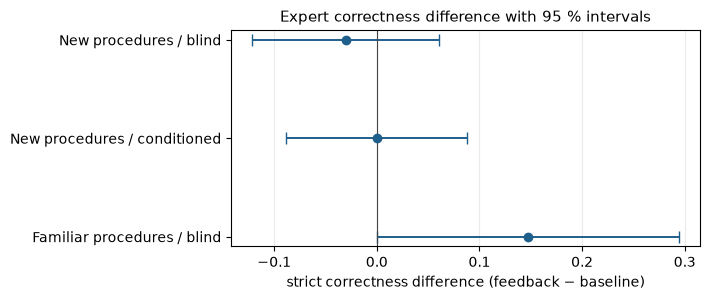

In [3]:
strict = SUMMARY[SUMMARY.metric.eq("strict")].copy()
lenient = SUMMARY[SUMMARY.metric.eq("lenient")].copy()
table = strict[["label", "n", "baseline_rate", "feedback_rate", "delta",
                "ci_lower", "ci_upper", "mcnemar_p", "n_discordant"]].copy()
table.columns = ["Arm", "n", "Baseline", "Feedback", "Delta", "CI low", "CI high",
                 "McNemar p", "Discordant"]
display(table.round(3))

order = strict.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.2, 3.1))
y = np.arange(len(order))
ax.errorbar(order["delta"], y,
            xerr=[order["delta"] - order["ci_lower"], order["ci_upper"] - order["delta"]],
            fmt="o", color="#1f5f8b", ecolor="#1f5f8b", capsize=4, lw=1.4)
ax.axvline(0, color="#444", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(order["label"], fontsize=10)
ax.set_xlabel("strict correctness difference (feedback − baseline)", fontsize=10)
ax.set_title("Expert correctness difference with 95 % intervals", fontsize=11)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(FIG / "human_eval_correctness.pdf")
fig.savefig(FIG / "human_eval_correctness.png", dpi=180)
plt.show()

**Reading it.** On the two *new-procedure* arms the intervals include zero: the
expert sees neither a reliable benefit nor a reliable harm. On the familiar-procedure
arm the point estimate is positive, but the interval touches zero and the next
sections show why it should not be read as a procedural improvement.

## 3. Preferences

A preference alone can hide two wrong answers, so the expert could choose *both
incorrect*; ties and *cannot judge* are also explicit.

,Arm,n,Feedback better,Baseline better,Equal,Both incorrect,Cannot judge,Net (feedback − baseline)
0,New procedures / blind,35,2,4,15,13,1,-2
1,New procedures / conditioned,35,7,3,11,13,1,4
2,Familiar procedures / blind,35,8,5,16,6,0,3


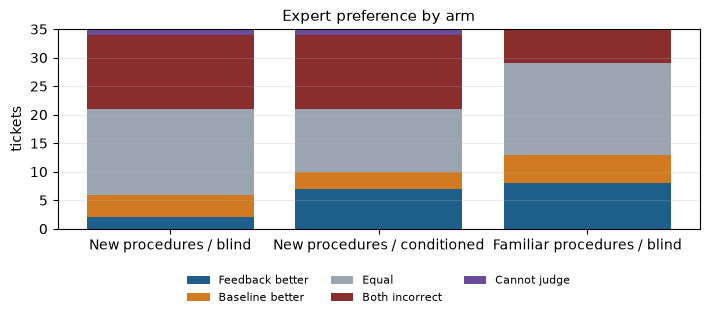

In [4]:
prefs = PREFS.copy()
display(prefs[["label", "n", "feedback_better", "baseline_better", "equal",
               "both_incorrect", "cannot_judge", "net_feedback_minus_baseline"]]
        .rename(columns={"label": "Arm", "n": "n", "feedback_better": "Feedback better",
                         "baseline_better": "Baseline better", "equal": "Equal",
                         "both_incorrect": "Both incorrect", "cannot_judge": "Cannot judge",
                         "net_feedback_minus_baseline": "Net (feedback − baseline)"}))

categories = [("feedback_better", "Feedback better"), ("baseline_better", "Baseline better"),
              ("equal", "Equal"), ("both_incorrect", "Both incorrect"),
              ("cannot_judge", "Cannot judge")]
fig, ax = plt.subplots(figsize=(7.2, 3.4))
bottom = np.zeros(len(prefs))
colors = ["#1f5f8b", "#d17a22", "#9aa5b1", "#8a2d2d", "#6b4c9a"]
for (column, label), color in zip(categories, colors):
    ax.bar(prefs["label"], prefs[column], bottom=bottom, label=label, color=color)
    bottom += prefs[column].to_numpy()
ax.set_ylabel("tickets", fontsize=10)
ax.set_title("Expert preference by arm", fontsize=11)
ax.legend(fontsize=8, frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIG / "human_eval_preferences.pdf")
fig.savefig(FIG / "human_eval_preferences.png", dpi=180)
plt.show()

## 4. Unsafe and missing steps

These flags capture what a similarity metric cannot see: a reply can be fluent and
similar to a recorded answer while containing a wrong or unsafe step, or while
omitting a step the procedure requires. Events are rare; the values are descriptive.

In [5]:
display(FLAGS[["label", "n", "baseline_unsafe_rate", "feedback_unsafe_rate",
               "baseline_missing_rate", "feedback_missing_rate"]]
        .rename(columns={"label": "Arm", "n": "n",
                         "baseline_unsafe_rate": "Baseline unsafe",
                         "feedback_unsafe_rate": "Feedback unsafe",
                         "baseline_missing_rate": "Baseline missing",
                         "feedback_missing_rate": "Feedback missing"}).round(3))

,Arm,n,Baseline unsafe,Feedback unsafe,Baseline missing,Feedback missing
0,New procedures / blind,35,0.029,0.057,0.029,0.0
1,New procedures / conditioned,35,0.086,0.086,0.000,0.0
2,Familiar procedures / blind,35,0.057,0.086,0.000,0.0


## 5. Answer length

The feedback replies on the familiar-procedure arm are much longer. If the expert
rewards detail rather than procedure, the correctness difference in that arm is
confounded. The matched subset keeps only pairs whose lengths differ by at most 100
characters.

,Arm,Baseline chars,Feedback chars,Difference,"Spearman(length, Δ)",p,n matched,Δ matched,n unmatched,Δ unmatched
0,New procedures / blind,451.114,449.629,-1.486,0.104,0.565,25,0.043,10,-0.200
1,New procedures / conditioned,424.286,429.857,5.571,-0.025,0.890,22,0.000,13,0.000
2,Familiar procedures / blind,523.086,695.743,172.657,0.626,0.000,13,0.000,22,0.227


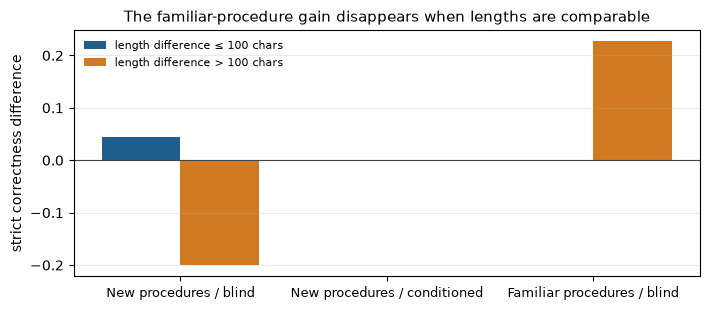

In [6]:
length = LENGTH.copy()
display(length[["label", "baseline_len", "feedback_len", "len_diff",
                "spearman_len_delta", "spearman_p", "n_matched", "delta_matched",
                "n_unmatched", "delta_unmatched"]]
        .rename(columns={"label": "Arm", "baseline_len": "Baseline chars",
                         "feedback_len": "Feedback chars", "len_diff": "Difference",
                         "spearman_len_delta": "Spearman(length, Δ)",
                         "spearman_p": "p", "n_matched": "n matched",
                         "delta_matched": "Δ matched", "n_unmatched": "n unmatched",
                         "delta_unmatched": "Δ unmatched"}).round(3))

x = np.arange(len(length))
width = 0.38
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.bar(x - width / 2, length["delta_matched"], width, label="length difference ≤ 100 chars",
       color="#1f5f8b")
ax.bar(x + width / 2, length["delta_unmatched"], width, label="length difference > 100 chars",
       color="#d17a22")
ax.axhline(0, color="#444", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(length["label"], fontsize=9)
ax.set_ylabel("strict correctness difference", fontsize=10)
ax.set_title("The familiar-procedure gain disappears when lengths are comparable", fontsize=11)
ax.legend(fontsize=8, frameon=False)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIG / "human_eval_length.pdf")
fig.savefig(FIG / "human_eval_length.png", dpi=180)
plt.show()

## 6. Expert versus automatic metric

The automatic metric is the cosine similarity between the generated reply and the
single recorded reference reply, differenced against the baseline answer. The
scatter uses hashed item identifiers; no ticket text is present.

,Arm,Automatic Δ,Expert Δ,Sign agreement,n non-zero,Spearman,p,AUC (preference),n non-tied
0,New procedures / blind,-0.026,-0.030,0.333,3,0.042,0.818,0.667,5
1,New procedures / conditioned,0.022,0.000,0.500,2,-0.037,0.835,0.048,10
2,Familiar procedures / blind,-0.088,0.147,0.143,7,-0.478,0.004,0.219,12


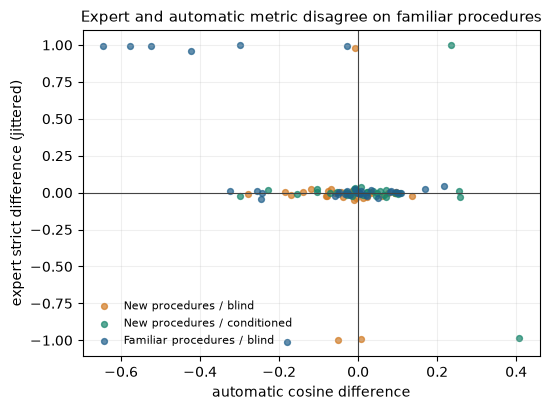

In [7]:
display(ALIGN[["label", "auto_mean", "human_mean", "sign_agreement", "sign_n",
               "spearman", "spearman_p", "auc_preference", "n_preference"]]
        .rename(columns={"label": "Arm", "auto_mean": "Automatic Δ",
                         "human_mean": "Expert Δ", "sign_agreement": "Sign agreement",
                         "sign_n": "n non-zero", "spearman": "Spearman",
                         "spearman_p": "p", "auc_preference": "AUC (preference)",
                         "n_preference": "n non-tied"}).round(3))

fig, ax = plt.subplots(figsize=(5.6, 4.2))
rng = np.random.default_rng(7)
colors = {"legacy_random/blind": "#1f5f8b",
          "disjoint_prefix/blind": "#d17a22",
          "disjoint_prefix/conditioned": "#16856b"}
for arm, group in ITEMS.groupby("arm"):
    jitter = rng.normal(0, 0.02, len(group))
    ax.scatter(group["auto_delta"], group["human_delta"] + jitter, s=18, alpha=0.7,
               color=colors.get(arm, "#777"), label=PRETTY.get(arm, arm))
ax.axhline(0, color="#444", lw=0.8)
ax.axvline(0, color="#444", lw=0.8)
ax.set_xlabel("automatic cosine difference", fontsize=10)
ax.set_ylabel("expert strict difference (jittered)", fontsize=10)
ax.set_title("Expert and automatic metric disagree on familiar procedures", fontsize=11)
ax.legend(fontsize=8, frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIG / "human_eval_alignment.pdf")
fig.savefig(FIG / "human_eval_alignment.png", dpi=180)
plt.show()

## 7. Sensitivity

The same effect under the strict and lenient definitions, with *cannot judge* removed,
and on the length-matched subset. The familiar-procedure signal is the only one that
changes materially, and it changes to zero.

In [8]:
pivot = SENS.pivot_table(index=["panel", "source"], columns="analysis", values="delta")
pivot.index = [PRETTY.get("/".join(index), "/".join(index)) for index in pivot.index]
display(pivot.rename_axis("Arm").rename_axis(None, axis=1).round(3))

,exclude_cannot,length_matched,lenient,strict
Arm,,,,
New procedures / blind,-0.030,0.043,-0.030,-0.030
New procedures / conditioned,0.000,0.000,0.029,0.000
Familiar procedures / blind,0.147,0.000,0.118,0.147


## 8. Population extrapolation

The sample contains only changed pairs, so the conditional effect is not the
population effect. The population value multiplies it by the measured share of
changed pairs in each arm. This is a design-based extrapolation, not an estimate
from the expert sample.

In [9]:
display(strict[["label", "changed_share", "delta", "population_delta",
                "population_ci_lower", "population_ci_upper"]]
        .rename(columns={"label": "Arm", "changed_share": "Changed share",
                         "delta": "Conditional Δ", "population_delta": "Population Δ",
                         "population_ci_lower": "CI low", "population_ci_upper": "CI high"})
        .round(3))

,Arm,Changed share,Conditional Δ,Population Δ,CI low,CI high
0,New procedures / blind,0.491,-0.030,-0.015,-0.059,0.030
2,New procedures / conditioned,0.455,0.000,0.000,-0.040,0.040
4,Familiar procedures / blind,0.877,0.147,0.129,0.000,0.258


## 9. What this answers from the reviews

| Reviewer point | What the notebook shows | Limit |
|---|---|---|
| R1-M8, R2-1: independent human check of procedural correctness | 105 blinded expert ratings, per reply, with flags and preferences | one rater; second pending |
| R2-16: similarity is not procedural correctness | automatic and expert deltas disagree on familiar procedures (Spearman −0.48, AUC 0.22) | strict arms have few non-zero deltas |
| R1-M6, R2-6, R2-7: intervals, direct tests, MDE | paired bootstrap intervals, exact McNemar, discordant counts, MDE | 2–7 discordant pairs per arm, underpowered |
| R2-11: blind scenario separately | all arms reported separately, never pooled | — |
| R1-M1, R2-5, R2-20: no overclaiming | no confirmed benefit or harm on new procedures; the familiar-procedure signal is length-driven | one rater |

## 10. Second rater

When a second rater completes the same package, the same pipeline adds agreement:
percent agreement, Cohen's kappa with a bootstrap interval, weighted kappa, PABAK
and AC1, plus a combined per-item effect. Until then this section stays pending.

In [10]:
raters = [p for p in RESULTS.parent.iterdir() if p.is_dir()]
other = [p.name for p in raters if p.name != "alberto"]
if other:
    print("Second rater found:", other)
    display(pd.read_csv(RESULTS.parent / other[0] / "agreement_agreement.csv").round(3))
    display(pd.read_csv(RESULTS.parent / other[0] / "combined_effect.csv").round(4))
else:
    print("Second rater pending. Agreement and the combined estimate are not yet available.")

Second rater pending. Agreement and the combined estimate are not yet available.


## 11. TL;DR

- On **new procedures** the expert sees neither a reliable benefit nor a reliable
  harm: strict correctness is 0.545 vs 0.515 with blind feedback and 0.559 vs 0.559
  with conditioned feedback, and both intervals include zero.
- On **familiar procedures** the expert preferred the feedback replies
  (0.647 → 0.794), but those replies were 173 characters longer and the preference
  tracks length (Spearman +0.63). Among length-matched pairs the difference is
  exactly zero.
- The automatic cosine metric and the expert point in opposite directions on that arm
  (automatic −0.088, expert +0.147), so neither is a clean measure of procedural
  correctness.
- **Status:** one expert, 105 tickets, descriptive; the second expert is pending and
  will provide inter-rater agreement.

Full write-up: `revision_ieee_access/02_human_study/HUMAN_EVAL_RESULTS.md`.